In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
data = {
    "Hours_Studied": [
        1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
        1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 11
    ],
    "Exam_Score": [
        35, 40, 45, 50, 55, 60, 65, 70, 75, 80,
        37, 43, 48, 53, 58, 63, 68, 73, 78, 85
    ]
}

df = pd.DataFrame(data)

print("Dataset preview:")
display(df.head())

print("\nDataset information:")
print(df.describe())

Dataset preview:


,Hours_Studied,Exam_Score
0,1.0,35
1,2.0,40
2,3.0,45
3,4.0,50
4,5.0,55



Dataset information:
       Hours_Studied  Exam_Score
count      20.000000   20.000000
mean        5.775000   59.050000
std         3.002083   15.066432
min         1.000000   35.000000
25%         3.375000   47.250000
50%         5.750000   59.000000
75%         8.125000   70.750000
max        11.000000   85.000000


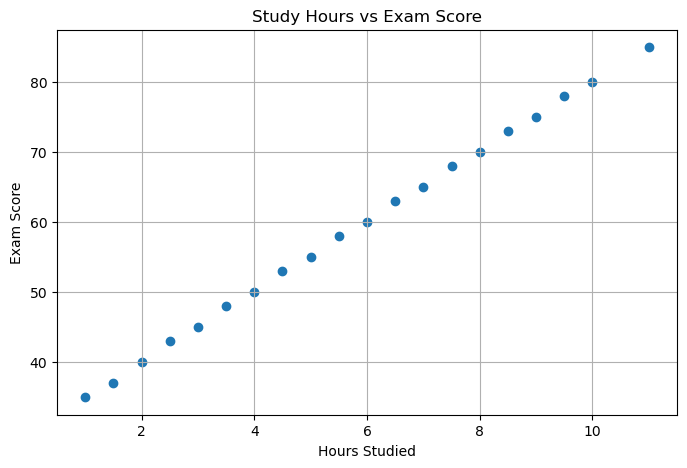

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Hours_Studied"], df["Exam_Score"])

plt.title("Study Hours vs Exam Score")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.grid(True)
plt.show()

In [4]:
X = df[["Hours_Studied"]]
y = df["Exam_Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed!")
print("Intercept:", round(model.intercept_, 2))
print("Slope:", round(model.coef_[0], 2))


Model training completed!
Intercept: 30.13
Slope: 5.0


Mean Absolute Error: 0.24
Mean Squared Error: 0.07
R2 Score: 1.0


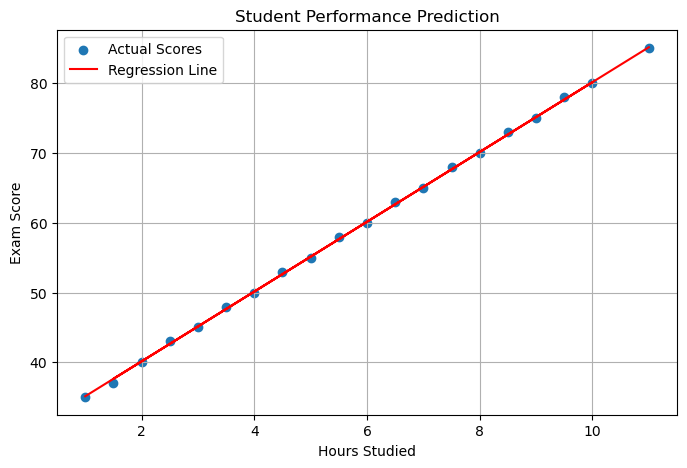

In [5]:
y_pred = model.predict(X_test)

print("Mean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("Mean Squared Error:", round(mean_squared_error(y_test, y_pred), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 3))

plt.figure(figsize=(8, 5))
plt.scatter(X, y, label="Actual Scores")
plt.plot(X, model.predict(X), color="red", label="Regression Line")

plt.title("Student Performance Prediction")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.legend()
plt.grid(True)
plt.show()


In [6]:
study_hours = pd.DataFrame({"Hours_Studied": [12]})

predicted_score = model.predict(study_hours)[0]

print(f"Study Hours: 7")
print(f"Predicted Exam Score: {predicted_score:.2f}")


Study Hours: 7
Predicted Exam Score: 90.18
